# BolsaLAB — Análisis exploratorio de datos (EDA)

`japan_training.parquet`.


## Secciones


*   Punto 1. ¿Cuál es la estructura y la calidad del conjunto de datos?
*   Punto 2. ¿Cómo se distribuyen las variables y la variable objetivo?


*   Punto 3. ¿Qué relaciones existen entre las variables?
*   Punto 4. ¿Qué diferencias existen entre los grupos sold = 0 y sold = 1?


*   Punto 5. ¿Qué asociaciones son estadísticamente significativas y qué problemas deben considerarse?
*   Punto 6 Conclusiones.







## Punto 1. ¿Cuál es la estructura y la calidad del conjunto de datos?

Resultados obtenidos
- El conjunto contiene 54.704 registros y 18 variables.
- No se encontraron valores faltantes.
- Se identificaron 329 filas duplicadas exactas.
- age_squared coincide con la edad al cuadrado en todas las filas.
- Las variables binarias presentan valores válidos de 0 y 1; las variables ordinales y numéricas se encuentran dentro de los rangos observados esperados.

El conjunto de datos presenta una estructura tabular de 54.704 observaciones y 18 variables, sin valores faltantes. Se identificaron 329 registros duplicados exactos, que deben investigarse antes de decidir si se eliminan, ya que podrían representar observaciones repetidas o individuos diferentes con características idénticas. La variable age_squared es consistente con el cuadrado de age.

In [20]:
import pandas as pd
import numpy as np

df = pd.read_parquet('/content/japan_training.parquet')

print("Dimensiones:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)
print("\nValores faltantes:")
print(df.isnull().sum())
print("\nDuplicados exactos:", df.duplicated().sum())
print("\nEstadísticas descriptivas:")
display(df.describe().T)

Dimensiones: (54704, 18)

Tipos de datos:
knows_interest             int64
knows_inflation            int64
knows_diversification      int64
knowledge_confidence       int64
overconfidence             int64
age                        int64
age_squared                int64
male                       int64
university                 int64
married                    int64
has_children               int64
urban                      int64
employed                   int64
risk_aversion            float64
short_term_view            int64
income_bracket             int64
assets_bracket             int64
sold                       int64
dtype: object

Valores faltantes:
knows_interest           0
knows_inflation          0
knows_diversification    0
knowledge_confidence     0
overconfidence           0
age                      0
age_squared              0
male                     0
university               0
married                  0
has_children             0
urban                    0
employ

,count,mean,std,min,25%,50%,75%,max
knows_interest,"54,704.0000",0.8213,0.3831,0.0000,1.0000,1.0000,1.0000,1.0000
knows_inflation,"54,704.0000",0.8061,0.3954,0.0000,1.0000,1.0000,1.0000,1.0000
knows_diversification,"54,704.0000",0.7805,0.4139,0.0000,1.0000,1.0000,1.0000,1.0000
knowledge_confidence,"54,704.0000",2.7111,1.0170,1.0000,2.0000,3.0000,3.0000,5.0000
overconfidence,"54,704.0000",0.0754,0.2641,0.0000,0.0000,0.0000,0.0000,1.0000
age,"54,704.0000",47.0135,12.3898,18.0000,37.0000,47.0000,56.0000,93.0000
age_squared,"54,704.0000","2,363.7707","1,219.6505",324.0000,"1,369.0000","2,209.0000","3,136.0000","8,649.0000"
male,"54,704.0000",0.6703,0.4701,0.0000,0.0000,1.0000,1.0000,1.0000
university,"54,704.0000",0.6505,0.4768,0.0000,0.0000,1.0000,1.0000,1.0000
married,"54,704.0000",0.6951,0.4604,0.0000,0.0000,1.0000,1.0000,1.0000


## Punto 2. ¿Cómo se distribuyen las variables y la variable objetivo?

Resultados obtenidos

Valor de sold	    Frecuencia	Porcentaje
0	                   43.835	    80,13 %
1	                   10.869	    19,87 %
Total	               54.704	    100 %

La variable sold presenta un desbalance entre sus dos categorías: el 80,13 % de los registros tiene valor 0 y el 19,87 % tiene valor 1. Esta diferencia debe considerarse al desarrollar modelos predictivos, porque un modelo podría obtener una exactitud elevada favoreciendo la clase mayoritaria. Por ello, además de accuracy, se deben evaluar precisión, recall, F1, ROC-AUC y PR-AUC.
La interpretación exacta de sold = 1 debe confirmarse con el diccionario de datos antes de equipararla con una venta total por pánico.

In [15]:
print("Distribución de sold:")
display(
    df['sold']
    .value_counts()
    .sort_index()
    .rename_axis('sold')
    .to_frame('frecuencia')
    .assign(
        porcentaje=lambda x: x['frecuencia'] / len(df) * 100
    )
)

# Frecuencias de variables categóricas
for col in df.columns:
    if df[col].nunique() <= 15:
        print(f"\nVariable: {col}")
        display(
            df[col]
            .value_counts()
            .sort_index()
            .rename_axis('valor')
            .to_frame('frecuencia')
            .assign(
                porcentaje=lambda x: x['frecuencia'] / len(df) * 100
            )
        )


Distribución de sold:


,frecuencia,porcentaje
sold,,
0,43835,80.1313
1,10869,19.8687



Variable: knows_interest


,frecuencia,porcentaje
valor,,
0,9774,17.8671
1,44930,82.1329



Variable: knows_inflation


...

,frecuencia,porcentaje
valor,,
1,995,1.8189
2,1572,2.8736
3,8200,14.9898
4,11823,21.6127
5,11183,20.4427
6,8613,15.7447
7,5289,9.6684
8,2574,4.7053
9,1707,3.1204



Variable: assets_bracket


,frecuencia,porcentaje
valor,,
1,7362,13.4579
2,8028,14.6753
3,5943,10.8639
4,5594,10.2259
5,6653,12.1618
6,4575,8.3632
7,5427,9.9207
8,5206,9.5167
9,3985,7.2847



Variable: sold


,frecuencia,porcentaje
valor,,
0,43835,80.1313
1,10869,19.8687


##Punto 3. ¿Qué relaciones existen entre las variables?
Resultados obtenidos
Las asociaciones más destacadas fueron:

Variables	                                            Spearman
knowledge_confidence – overconfidence	                  0,421
knows_interest – knows_inflation	                      0,352
income_bracket – assets_bracket	                        0,345
age – assets_bracket	                                  0,332
knows_inflation – knows_diversification	                0,312

Las correlaciones muestran relaciones positivas entre algunas variables de conocimiento financiero, confianza y situación económica. La asociación más alta corresponde a la confianza en los conocimientos financieros y la variable de exceso de confianza, con un coeficiente de 0,421. También existe una relación positiva entre los rangos de ingresos y activos, con un coeficiente de 0,345.
Estas asociaciones no implican causalidad. Además, la correlación entre knowledge_confidence y overconfidence debe interpretarse teniendo en cuenta cómo se construyó esta última variable.



,knows_interest,knows_inflation,knows_diversification,knowledge_confidence,overconfidence,age,age_squared,male,university,married,has_children,urban,employed,risk_aversion,short_term_view,income_bracket,assets_bracket,sold
knows_interest,1.0000,0.3520,0.2550,0.1220,-0.1100,0.0080,0.0080,0.1360,0.1540,0.0320,0.0040,0.0200,-0.0050,0.0130,-0.0960,0.1250,0.1520,-0.0640
knows_inflation,0.3520,1.0000,0.3120,0.1960,-0.0510,0.1690,0.1690,0.1780,0.1540,0.0390,0.0320,0.0250,-0.0680,0.0330,-0.0920,0.1160,0.2320,-0.0640
knows_diversification,0.2550,0.3120,1.0000,0.1220,-0.1440,0.0050,0.0050,0.0770,0.1010,0.0260,0.0050,0.0080,0.0250,0.0070,-0.0960,0.1020,0.1120,-0.1080
knowledge_confidence,0.1220,0.1960,0.1220,1.0000,0.4210,0.1310,0.1310,0.1950,0.1000,0.0600,0.0520,0.0120,-0.0880,0.0570,-0.0560,0.1140,0.2800,0.0540
overconfidence,-0.1100,-0.0510,-0.1440,0.4210,1.0000,0.0240,0.0240,0.0550,0.0240,0.0040,0.0110,0.0090,-0.0470,0.0250,-0.0170,0.0220,0.0820,0.0600
age,0.0080,0.1690,0.0050,0.1310,0.0240,1.0000,1.0000,0.1910,-0.1250,0.1490,0.2430,-0.0310,-0.3470,0.1400,-0.0150,-0.0440,0.3320,0.0540
age_squared,0.0080,0.1690,0.0050,0.1310,0.0240,1.0000,1.0000,0.1910,-0.1250,0.1490,0.2430,-0.0310,-0.3470,0.1400,-0.0150,-0.0440,0.3320,0.0540
male,0.1360,0.1780,0.0770,0.1950,0.0550,0.1910,0.1910,1.0000,0.1360,0.0860,0.0520,-0.0230,-0.1070,0.0730,-0.0790,0.0690,0.0930,0.1360
university,0.1540,0.1540,0.1010,0.1000,0.0240,-0.1250,-0.1250,0.1360,1.0000,0.0540,-0.0320,0.0600,0.0210,0.0620,-0.0820,0.2140,0.1730,-0.0300
married,0.0320,0.0390,0.0260,0.0600,0.0040,0.1490,0.1490,0.0860,0.0540,1.0000,0.4460,-0.0310,0.0150,-0.0000,-0.0420,0.3970,0.1380,-0.0080


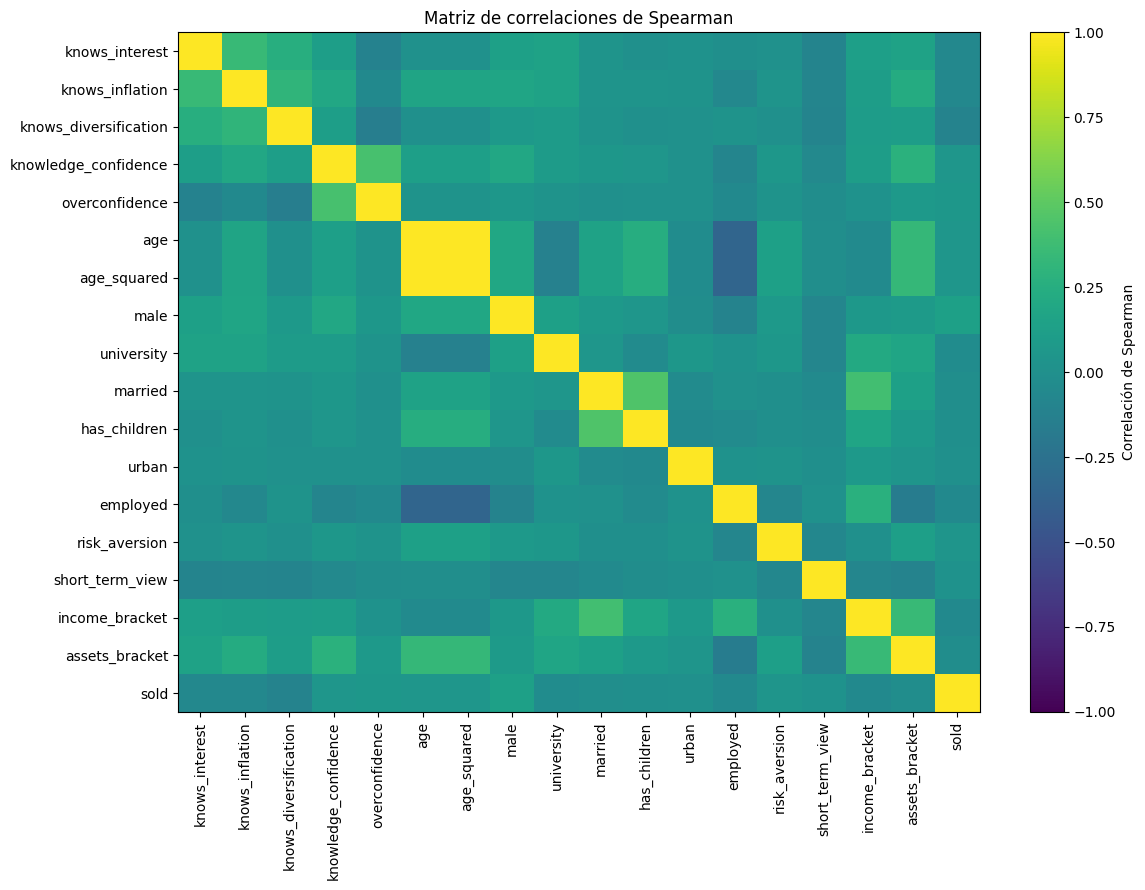

,variable_1,variable_2,correlacion
3,age,age_squared,1.0000
8,married,has_children,0.4461
2,knowledge_confidence,overconfidence,0.4209
9,married,income_bracket,0.3973
0,knows_interest,knows_inflation,0.3515
6,age_squared,employed,-0.3472
4,age,employed,-0.3472
10,income_bracket,assets_bracket,0.3454
5,age,assets_bracket,0.3323
7,age_squared,assets_bracket,0.3323


In [16]:
import matplotlib.pyplot as plt

corr = df.corr(method='spearman', numeric_only=True)

display(corr.round(3))

plt.figure(figsize=(12, 9))
plt.imshow(corr, aspect='auto', vmin=-1, vmax=1)
plt.colorbar(label='Correlación de Spearman')
plt.xticks(range(len(corr.columns)), corr.columns,
           rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title('Matriz de correlaciones de Spearman')
plt.tight_layout()
plt.show()

# Pares con correlación absoluta igual o superior a 0,30
pares = []
columnas = corr.columns.tolist()

for i in range(len(columnas)):
    for j in range(i + 1, len(columnas)):
        r = corr.iloc[i, j]
        if abs(r) >= 0.30:
            pares.append({
                'variable_1': columnas[i],
                'variable_2': columnas[j],
                'correlacion': r
            })

display(
    pd.DataFrame(pares)
    .sort_values('correlacion',
                 key=lambda x: x.abs(),
                 ascending=False)
)


##Punto 4. ¿Qué diferencias existen entre los grupos sold = 0 y sold = 1?

Resultados obtenidos
Variable	                  sold = 0	              sold = 1
Edad media	                46,67	                  48,41
Aversión al riesgo	        0,541	                  0,563
Confianza financiera	      2,684	                  2,821
Visión de corto plazo	      2,403	                  2,456
Rango de ingresos	          5,294	5,089
Rango de activos	          4,755	4,667

Otras diferencias relevantes en la proporción de sold = 1:

Característica	                                          Tasa
Conoce la diversificación: sí	                            17,59 %
Conoce la diversificación: no	                            27,99 %
Exceso de confianza: sí	                                  28,19 %
Exceso de confianza: no	                                  19,19 %
Hombre	                                                  23,68 %
No hombre	                                                12,12 %
Empleado	                                                19,24 %
No empleado	                                              26,94 %

Los registros con sold = 1 presentan una edad media y una aversión al riesgo ligeramente superiores. También se observan tasas mayores de sold = 1 entre quienes tienen exceso de confianza y entre quienes no identifican correctamente la diversificación. Sin embargo, estas diferencias son descriptivas: no demuestran que esas características provoquen la venta. Las variables deben analizarse conjuntamente para evaluar si las asociaciones se mantienen.

In [17]:
comparacion = df.groupby('sold').mean(numeric_only=True).T

comparacion.columns = [
    f'media_sold_{c}' for c in comparacion.columns
]

display(comparacion)

# Tasas de sold=1 para variables binarias
variables = [
    'knows_interest',
    'knows_inflation',
    'knows_diversification',
    'overconfidence',
    'male',
    'university',
    'married',
    'has_children',
    'urban',
    'employed'
]

for col in variables:
    print(f'\nTasa de sold=1 según {col}:')
    display(
        df.groupby(col)['sold']
        .agg(['count', 'mean'])
        .rename(columns={
            'count': 'observaciones',
            'mean': 'tasa_sold_1'
        })
    )


,media_sold_0,media_sold_1
knows_interest,0.8334,0.7725
knows_inflation,0.8187,0.7550
knows_diversification,0.8028,0.6909
knowledge_confidence,2.6840,2.8207
overconfidence,0.0676,0.1070
age,46.6671,48.4105
age_squared,"2,326.7213","2,513.1920"
male,0.6385,0.7989
university,0.6575,0.6222
married,0.6970,0.6874



Tasa de sold=1 según knows_interest:


,observaciones,tasa_sold_1
knows_interest,,
0,9774,0.2530
1,44930,0.1869



Tasa de sold=1 según knows_inflation:


,observaciones,tasa_sold_1
knows_inflation,,
0,10609,0.2510
1,44095,0.1861


...

,observaciones,tasa_sold_1
has_children,,
0,28705,0.1992
1,25999,0.1981



Tasa de sold=1 según urban:


,observaciones,tasa_sold_1
urban,,
0,46085,0.1982
1,8619,0.2012



Tasa de sold=1 según employed:


,observaciones,tasa_sold_1
employed,,
0,4439,0.2694
1,50265,0.1924


## Punto 5. ¿Qué asociaciones son estadísticamente significativas y qué problemas deben considerarse?
Resultados obtenidos
Después de aplicar la corrección de Holm, se encontraron asociaciones estadísticamente significativas entre sold y:
- Sexo (male).
- Conocimiento de diversificación (knows_diversification).
- Conocimiento de inflación (knows_inflation).
- Conocimiento del interés compuesto (knows_interest).
- Exceso de confianza (overconfidence).
- Situación laboral (employed).
- Formación universitaria (university).
No se mantuvieron asociaciones estadísticamente significativas con married, has_children y urban tras el ajuste.
Los tamaños de efecto medidos con V de Cramér fueron pequeños en las asociaciones analizadas. Por ejemplo, male presentó \(V \approx 0,136\), mientras que knows_diversification presentó \(V \approx 0,108\).

Las pruebas chi-cuadrado identifican asociaciones estadísticamente significativas entre la variable objetivo y varias características personales y financieras. Sin embargo, los tamaños de efecto son pequeños, por lo que la significación estadística no debe confundirse con una relación de gran magnitud. La corrección de Holm permite controlar el riesgo de falsos positivos derivado de realizar varias pruebas.
Antes de entrenar modelos, deben verificarse la definición de sold, el origen de los duplicados y la codificación de las variables. Las conclusiones actuales describen asociaciones y no permiten establecer relaciones causales.

In [18]:
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

variables = [
    'knows_interest',
    'knows_inflation',
    'knows_diversification',
    'overconfidence',
    'male',
    'university',
    'married',
    'has_children',
    'urban',
    'employed'
]

resultados = []

for col in variables:
    tabla = pd.crosstab(df[col], df['sold'])

    chi2, p, gl, esperados = chi2_contingency(tabla)

    n = tabla.to_numpy().sum()
    r, k = tabla.shape
    v_cramer = np.sqrt(
        chi2 / (n * min(r - 1, k - 1))
    )

    resultados.append({
        'variable': col,
        'chi2': chi2,
        'p_original': p,
        'V_Cramer': v_cramer
    })

resultados = pd.DataFrame(resultados)

resultados['p_Holm'] = multipletests(
    resultados['p_original'],
    method='holm'
)[1]

resultados['significativo'] = resultados['p_Holm'] < 0.05

display(resultados.sort_values('p_Holm'))


,variable,chi2,p_original,V_Cramer,p_Holm,significativo
4,male,"1,013.4596",0.0000,0.1361,0.0000,True
2,knows_diversification,635.9317,0.0000,0.1078,0.0000,True
1,knows_inflation,225.9337,0.0000,0.0643,0.0000,True
0,knows_interest,220.2193,0.0000,0.0634,0.0000,True
3,overconfidence,193.3852,0.0000,0.0595,0.0000,True
9,employed,151.3714,0.0000,0.0526,0.0000,True
5,university,47.4717,0.0000,0.0295,0.0000,True
6,married,3.7494,0.0528,0.0083,0.1585,False
7,has_children,0.1060,0.7447,0.0014,1.0000,False
8,urban,0.3819,0.5366,0.0026,1.0000,False


## Punto 6 Conclusiones.
El dataset contiene 54.704 registros sin valores faltantes, pero con 329 duplicados exactos que requieren revisión antes de cualquier eliminación. La variable sold está desbalanceada, con un 19,87 % de registros positivos. El análisis exploratorio identifica asociaciones entre la venta registrada y características como sexo, conocimiento financiero, exceso de confianza y empleo, aunque los tamaños de efecto son pequeños.
El siguiente paso sería preparar los datos para el modelado y comparar varios clasificadores con métricas adecuadas para clases desbalanceadas. Antes de presentar los resultados como una réplica del artículo de referencia, es necesario confirmar que sold representa la misma conducta de venta que la variable estudiada en ese artículo.

In [19]:
print(f"Observaciones: {len(df):,}")
print(f"Variables: {df.shape[1]}")
print(f"Valores faltantes: {int(df.isna().sum().sum()):,}")
print(f"Duplicados exactos: {int(df.duplicated().sum()):,}")
print(f"Proporción sold=1: {(df.sold == 1).mean():.2%}")

Observaciones: 54,704
Variables: 18
Valores faltantes: 0
Duplicados exactos: 329
Proporción sold=1: 19.87%


## Exportación de resultados
Los CSV quedan en `/content/bolsalab_resultados/` y pueden descargarse desde el panel de archivos de Colab.

In [10]:
salida = Path("/content/bolsalab_resultados")
salida.mkdir(exist_ok=True)
df.describe().T.to_csv(salida/"estadistica_descriptiva.csv")
corr.to_csv(salida/"correlaciones_spearman.csv")
tabla_frecuencias.to_csv(salida/"frecuencias_categoricas.csv", index=False)
tabla_tasas.to_csv(salida/"tasas_sold_con_intervalos.csv", index=False)
tabla_tests.to_csv(salida/"pruebas_chi2_holm.csv", index=False)
print("Guardado en:", salida)
for f in sorted(salida.iterdir()):
    print(f.name)


Guardado en: /content/bolsalab_resultados
correlaciones_spearman.csv
estadistica_descriptiva.csv
frecuencias_categoricas.csv
pruebas_chi2_holm.csv
tasas_sold_con_intervalos.csv
